# Live monitor of an iterative AIMMD-TIS run

Refreshes every `REFRESH_S` seconds while `run_iterative.py` writes to `OUT`, and stops refreshing on its own once the run has ended. Interrupt the kernel to stop earlier. Each refresh shows:
- **progress:** stage completion per iteration, TIS ensembles finished, the latest stage and training lines of `run.log`;
- **convergence:**
  - RPE free energy against the true potential;
  - committor projection against theory, for the sampling model $q_k$, the trained $q_{k+1}$ and the model-free shot committor;
  - calibration;
  - the model change $\Delta q$ against the stopping tolerance;
- **reactive fraction and rates:** $P(\lambda_B|\lambda_0)$ through the joined interface, and the rates, with block-bootstrap errors. These are computed once per finished iteration and cached in `rpe_it{k}/p_bootstrap.json`.
- **crossing probabilities:** $P(\lambda|\lambda_0)$ per iteration in that iteration's $q_k$, with bootstrap bands. For all iterations in one common coordinate, run `python convergence.py --out <run>` after the run.
- **figures:** the newest iteration's free energy, committor projection, committor slice and along-$q$.

Only files written by finished stages are read, so the running job is never disturbed. Start a run with, for example:
```bash
python run_iterative.py --out results_it_100_steps --stage iterate --tis-steps 100 --until-converged > results_it_100_steps/run.log 2>&1 &
```

In [4]:
from pathlib import Path
import time
import matplotlib.pyplot as plt
from IPython.display import display, clear_output, Image, Markdown

import run_iterative as ri
import monitor

OUT = Path("results_harmonics20")   # run folder to monitor
REFRESH_S = 120                       # seconds between refreshes
N_BOOTSTRAP = 30                      # bootstrap samples for the P / rate errors
LIVE = True                           # False: draw once and stop

cfg = ri.load_run_config(OUT)        # the config the run was started with
wf = ri.IterativeAimmdTIS(cfg, OUT, n_workers=1)

Setting up Langevin BAOAB integrator for toy system...
seed used for harmonic oscilattors 123
pot dimensions without oscillators: 2
harmonic oscillators omegas:
array([0.        , 0.        , 1.        , 1.5       , 7.57175348,
       4.28911468, 3.81481163, 6.41051815, 7.75575176, 5.38485168,
       9.84611359, 7.47863791, 5.84745521, 5.13694015, 4.74542413,
       7.83239766, 5.50857796, 2.47742317, 5.18435404, 7.90396325,
       3.45993384, 3.40361405])
Setting up Langevin BAOAB integrator for toy system...
Setting up toy engine for wolfe-quapp...
Creating snapshot template for toy system...
Defining states for wolfe-quapp...


**results_harmonics20** · not running · updated 13:50:22

,iteration,ensembles,tis,rpe,train,analysis
0,0,9/9,True,True,True,True
1,1,16/16,True,True,True,True
2,2,14/14,True,True,True,True
3,3,13/13,True,True,True,True
4,4,15/15,True,True,True,True
5,5,14/14,True,True,True,True
6,6,16/16,True,True,True,True
7,7,16/16,True,True,True,True
8,8,16/16,True,True,True,True
9,9,15/15,True,True,True,True


[it12] Gate selection stabilized (selected count constant at 2 over last 30 epochs) -- freezing gates deterministically at epoch 50, fine-tune capped at 150 more epochs.
[it12] Early stopping at epoch 88 (patience 30, best EMA val=2.2557e+00).
[it11] analysis: fe_rmse_kT=0.506, fe_rmse_weighted_kT=0.469, fe_coverage=0.666, shot_proj_rmse_logit=0.9, shot_proj_rmse_pB=0.0465, q_k_proj_rmse_logit=0.53, q_k_proj_rmse_pB=0.0187, q_k_calib_mean=0
[it12] Epoch 88/300 | Train=2.2544e+00 Test=2.2557e+00 Fit=1.9624e+00 Qsm=1.695e+04 PredictiveTrain=1.9780e+00 PredictiveTest=1.9793e+00 LR=5.00e-05 Batch=16384


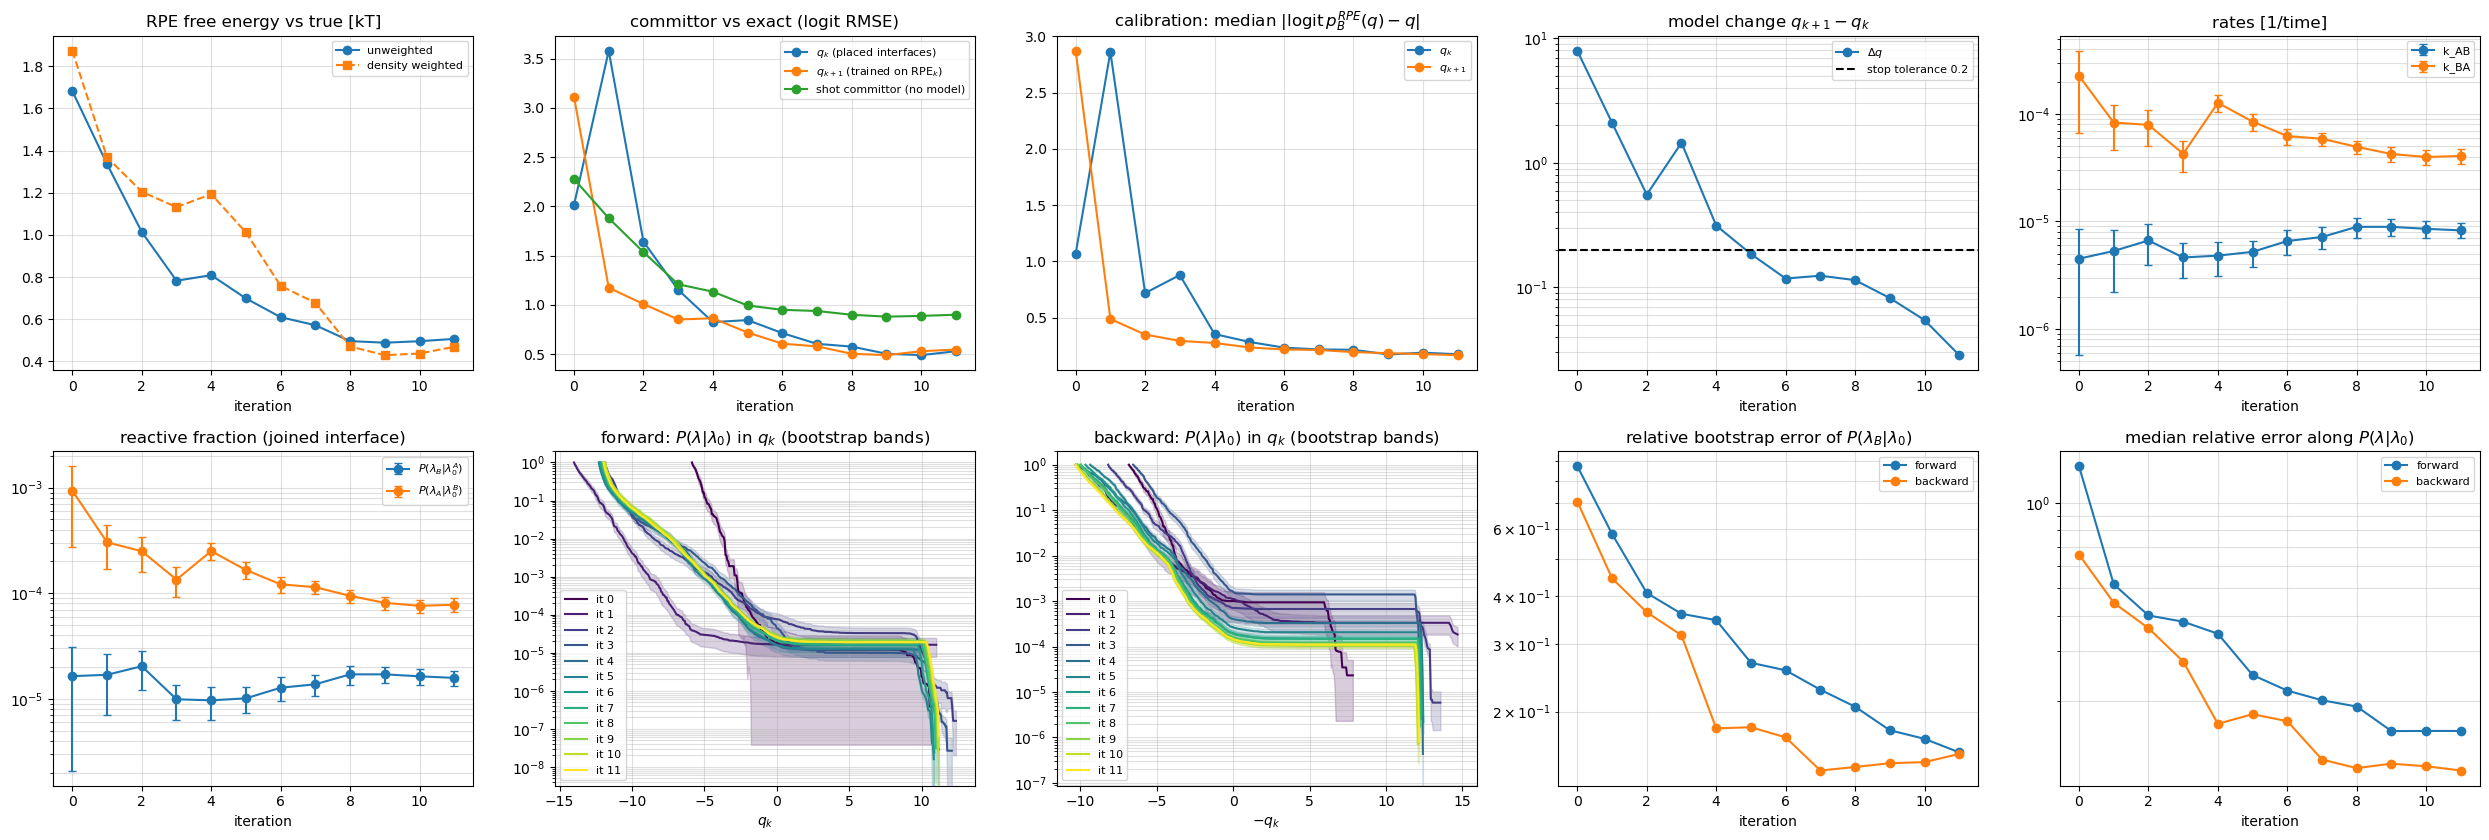

### Latest analysed iteration: 11

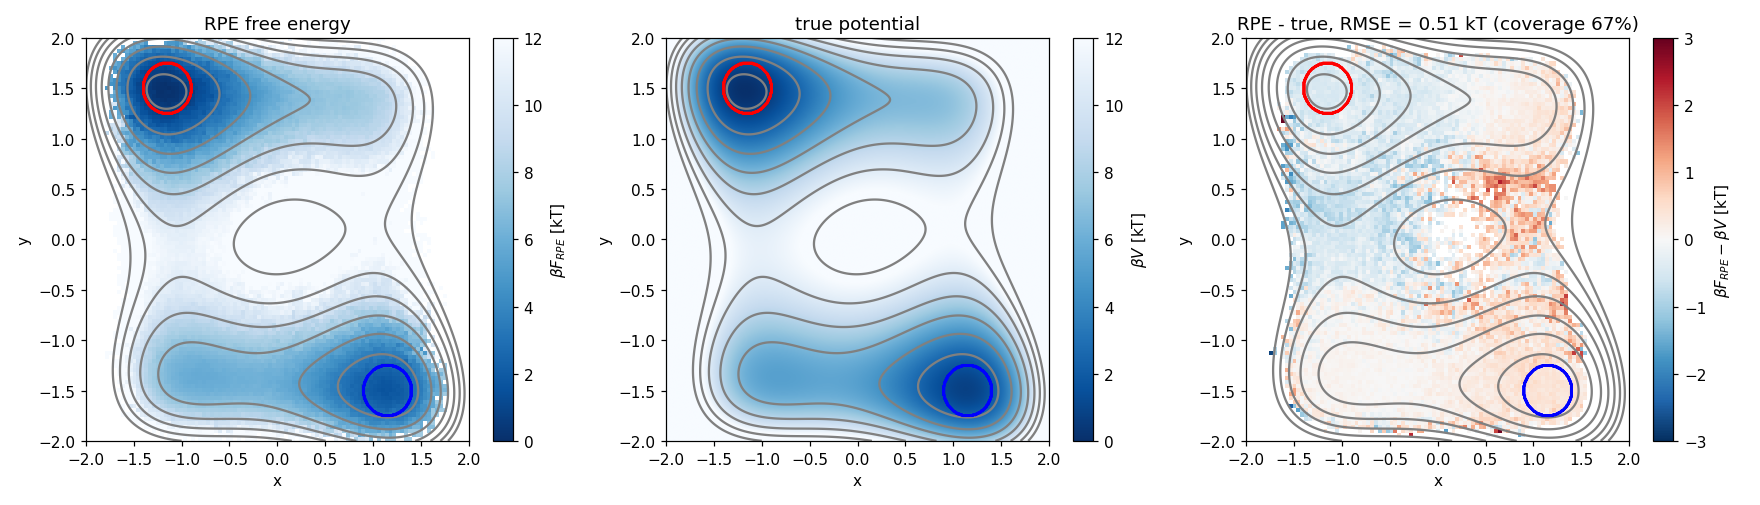

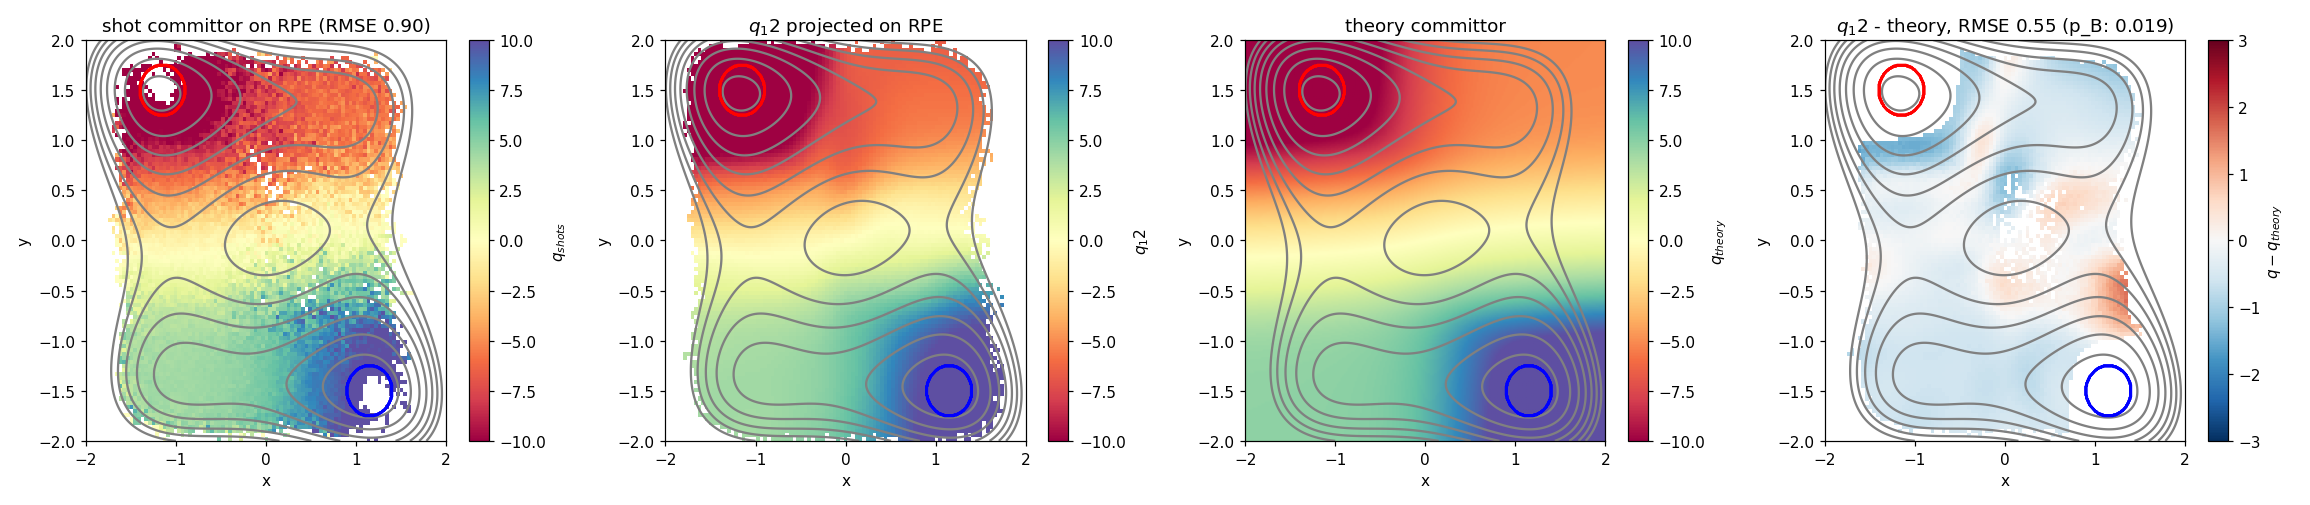

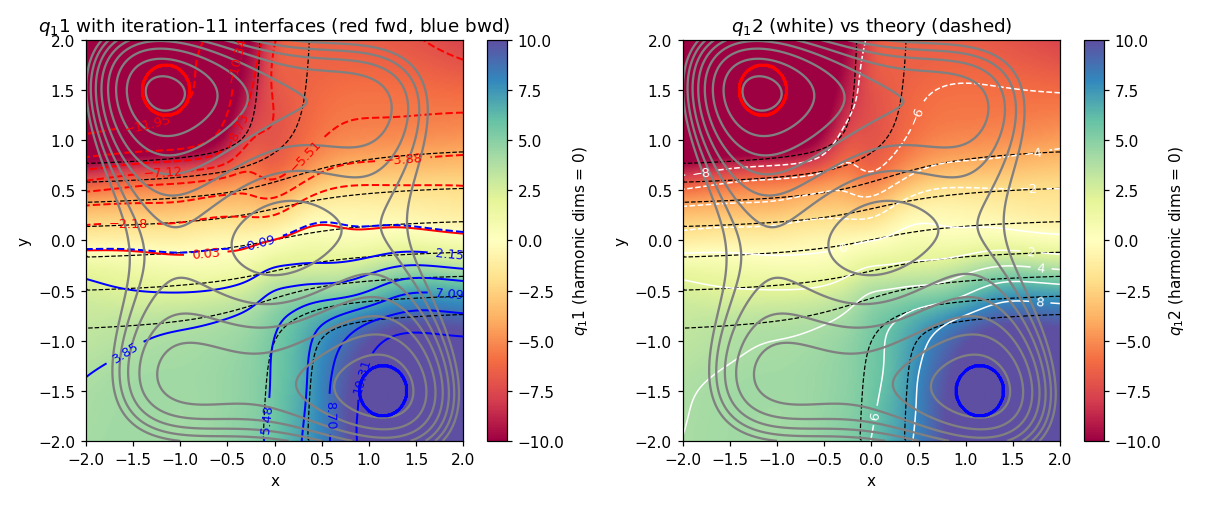

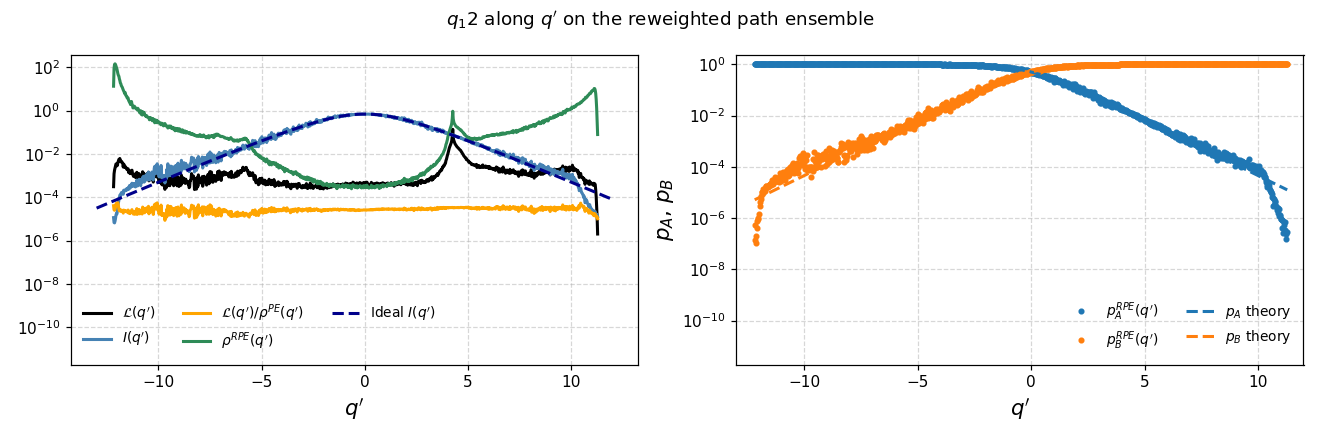

In [5]:
while True:
    running = monitor.is_running(OUT)
    try:
        monitor.update_bootstrap(wf, N_BOOTSTRAP)
    except Exception as exc:  # an iteration still being written
        print("bootstrap skipped this refresh:", exc)
    clear_output(wait=True)
    display(Markdown(f"**{OUT}** · {'running' if running else 'not running'} · updated {time.strftime('%H:%M:%S')}"))
    display(monitor.iteration_status(OUT))
    for line in monitor.latest_log_lines(OUT):
        print(line[:200])
    fig, df = monitor.dashboard(OUT, cfg)
    if fig is not None:
        display(fig)
        plt.close(fig)
    k, paths = monitor.latest_figures(OUT)
    if k is not None:
        display(Markdown(f"### Latest analysed iteration: {k}"))
        for p in paths:
            display(Image(filename=str(p)))
    if not (LIVE and running):
        break
    time.sleep(REFRESH_S)

In [6]:
# Metrics so far as a table
monitor.collect(OUT)

,iteration,k_AB,k_BA,c_AB,P_forward,P_backward,tis_weight_before_joined_fwd,tis_weight_before_joined_bwd,fe_rmse_kT,fe_rmse_weighted_kT,...,q_next_grad_mag_transition,delta_q_rms,channel_right_frac_fwd,n_reactive_fwd,channel_right_frac_bwd,n_reactive_bwd,P_forward_err,k_AB_err,P_backward_err,k_BA_err
0,0,0.000005,0.000226,0.338658,0.000016,0.000937,0.523082,0.620476,1.682659,1.873573,...,10.106759,7.939397,0.000000,106,0.006390,313,0.000014,0.000004,0.000661,0.000160
1,1,0.000005,0.000083,1.736292,0.000017,0.000304,0.522483,0.540180,1.336102,1.367925,...,5.499138,2.098123,0.000000,665,0.057441,383,0.000010,0.000003,0.000135,0.000037
2,2,0.000007,0.000079,1.274510,0.000020,0.000250,0.510428,0.408004,1.013580,1.204802,...,4.795083,0.556675,0.034615,780,0.406863,612,0.000008,0.000003,0.000091,0.000029
3,3,0.000005,0.000043,1.231496,0.000010,0.000135,0.362662,0.426024,0.782341,1.131517,...,5.543618,1.451619,0.034527,782,0.425197,635,0.000004,0.000002,0.000043,0.000014
4,4,0.000005,0.000127,1.122961,0.000010,0.000251,0.318867,0.166530,0.808752,1.193594,...,5.715737,0.313854,0.068156,895,0.452949,797,0.000003,0.000002,0.000045,0.000023
5,5,0.000005,0.000085,1.187643,0.000010,0.000166,0.308012,0.186812,0.698294,1.011565,...,5.916683,0.185470,0.131021,1038,0.413043,874,0.000003,0.000001,0.000030,0.000016
6,6,0.000007,0.000062,1.259813,0.000013,0.000122,0.309938,0.196203,0.609276,0.757811,...,6.072964,0.117809,0.110534,1348,0.340187,1070,0.000003,0.000002,0.000021,0.000011
7,7,0.000007,0.000059,1.348437,0.000014,0.000114,0.306251,0.192697,0.571105,0.677622,...,6.084995,0.124155,0.086906,1726,0.284375,1280,0.000003,0.000002,0.000016,0.000008
8,8,0.000009,0.000049,1.433743,0.000017,0.000094,0.308844,0.188669,0.495790,0.470120,...,6.163384,0.114391,0.078132,2099,0.255464,1464,0.000004,0.000002,0.000014,0.000007
9,9,0.000009,0.000042,1.424615,0.000017,0.000081,0.308505,0.194646,0.488099,0.428997,...,6.214806,0.082123,0.070842,2315,0.236923,1625,0.000003,0.000002,0.000012,0.000006
